In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate and load the original dataset
possible_paths = [
    Path("data/raw/bank-full.csv"),
    Path("../data/raw/bank-full.csv")
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("Could not locate data/raw/bank-full.csv")

df = pd.read_csv(DATA_PATH, sep=";")

# Create a numerical representation of the target for analysis
df["subscribed"] = df["y"].map({"no": 0, "yes": 1})

categorical_cols = [
    col for col in df.select_dtypes(include="object").columns
    if col != "y"
]

numeric_cols = df.select_dtypes(include="number").columns.tolist()
numeric_cols.remove("subscribed")

print(f"Dataset: {df.shape[0]:,} rows × {df.shape[1] - 1} original attributes")
print(f"Categorical features: {len(categorical_cols)}")
print(f"Numerical features: {len(numeric_cols)}")

Dataset: 45,211 rows × 17 original attributes
Categorical features: 9
Numerical features: 7


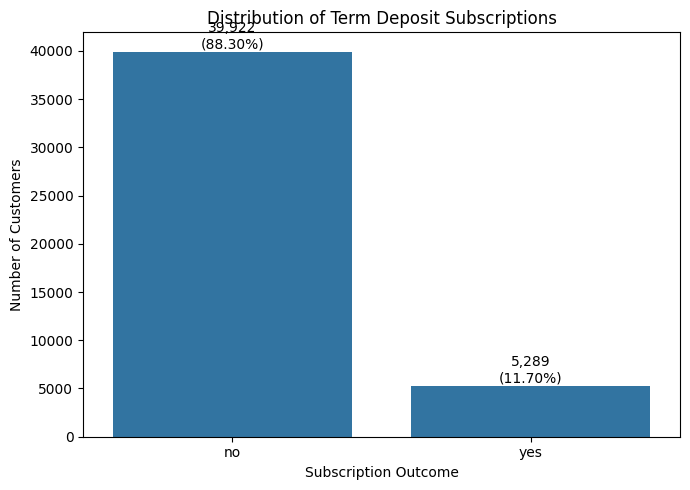

In [2]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax)

ax.set_title("Distribution of Term Deposit Subscriptions")
ax.set_xlabel("Subscription Outcome")
ax.set_ylabel("Number of Customers")

for i, value in enumerate(target_counts.values):
    percentage = value / len(df) * 100
    ax.text(i, value, f"{value:,}\n({percentage:.2f}%)",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

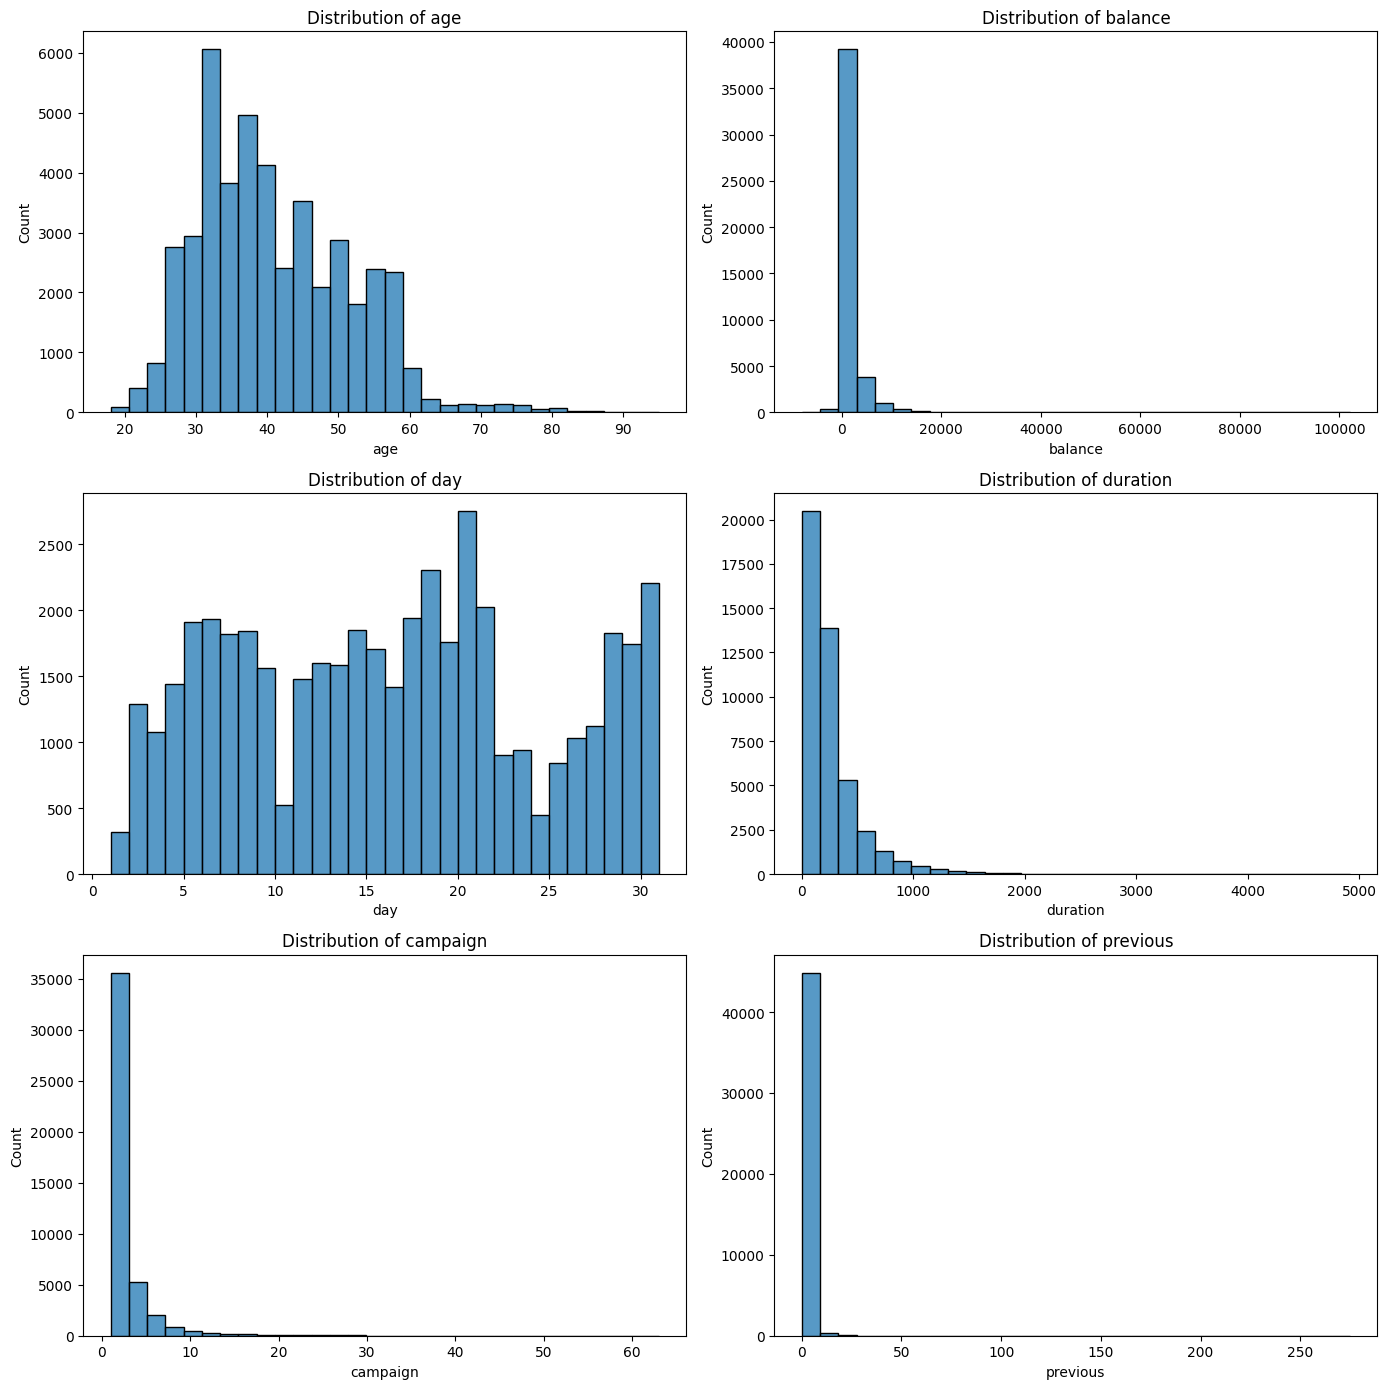

In [3]:
# pdays is handled separately because -1 is a special sentinel value.
plot_cols = [col for col in numeric_cols if col != "pdays"]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    sns.histplot(data=df, x=col, bins=30, ax=ax)
    ax.set_title(f"Distribution of {col}")

for ax in axes[len(plot_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

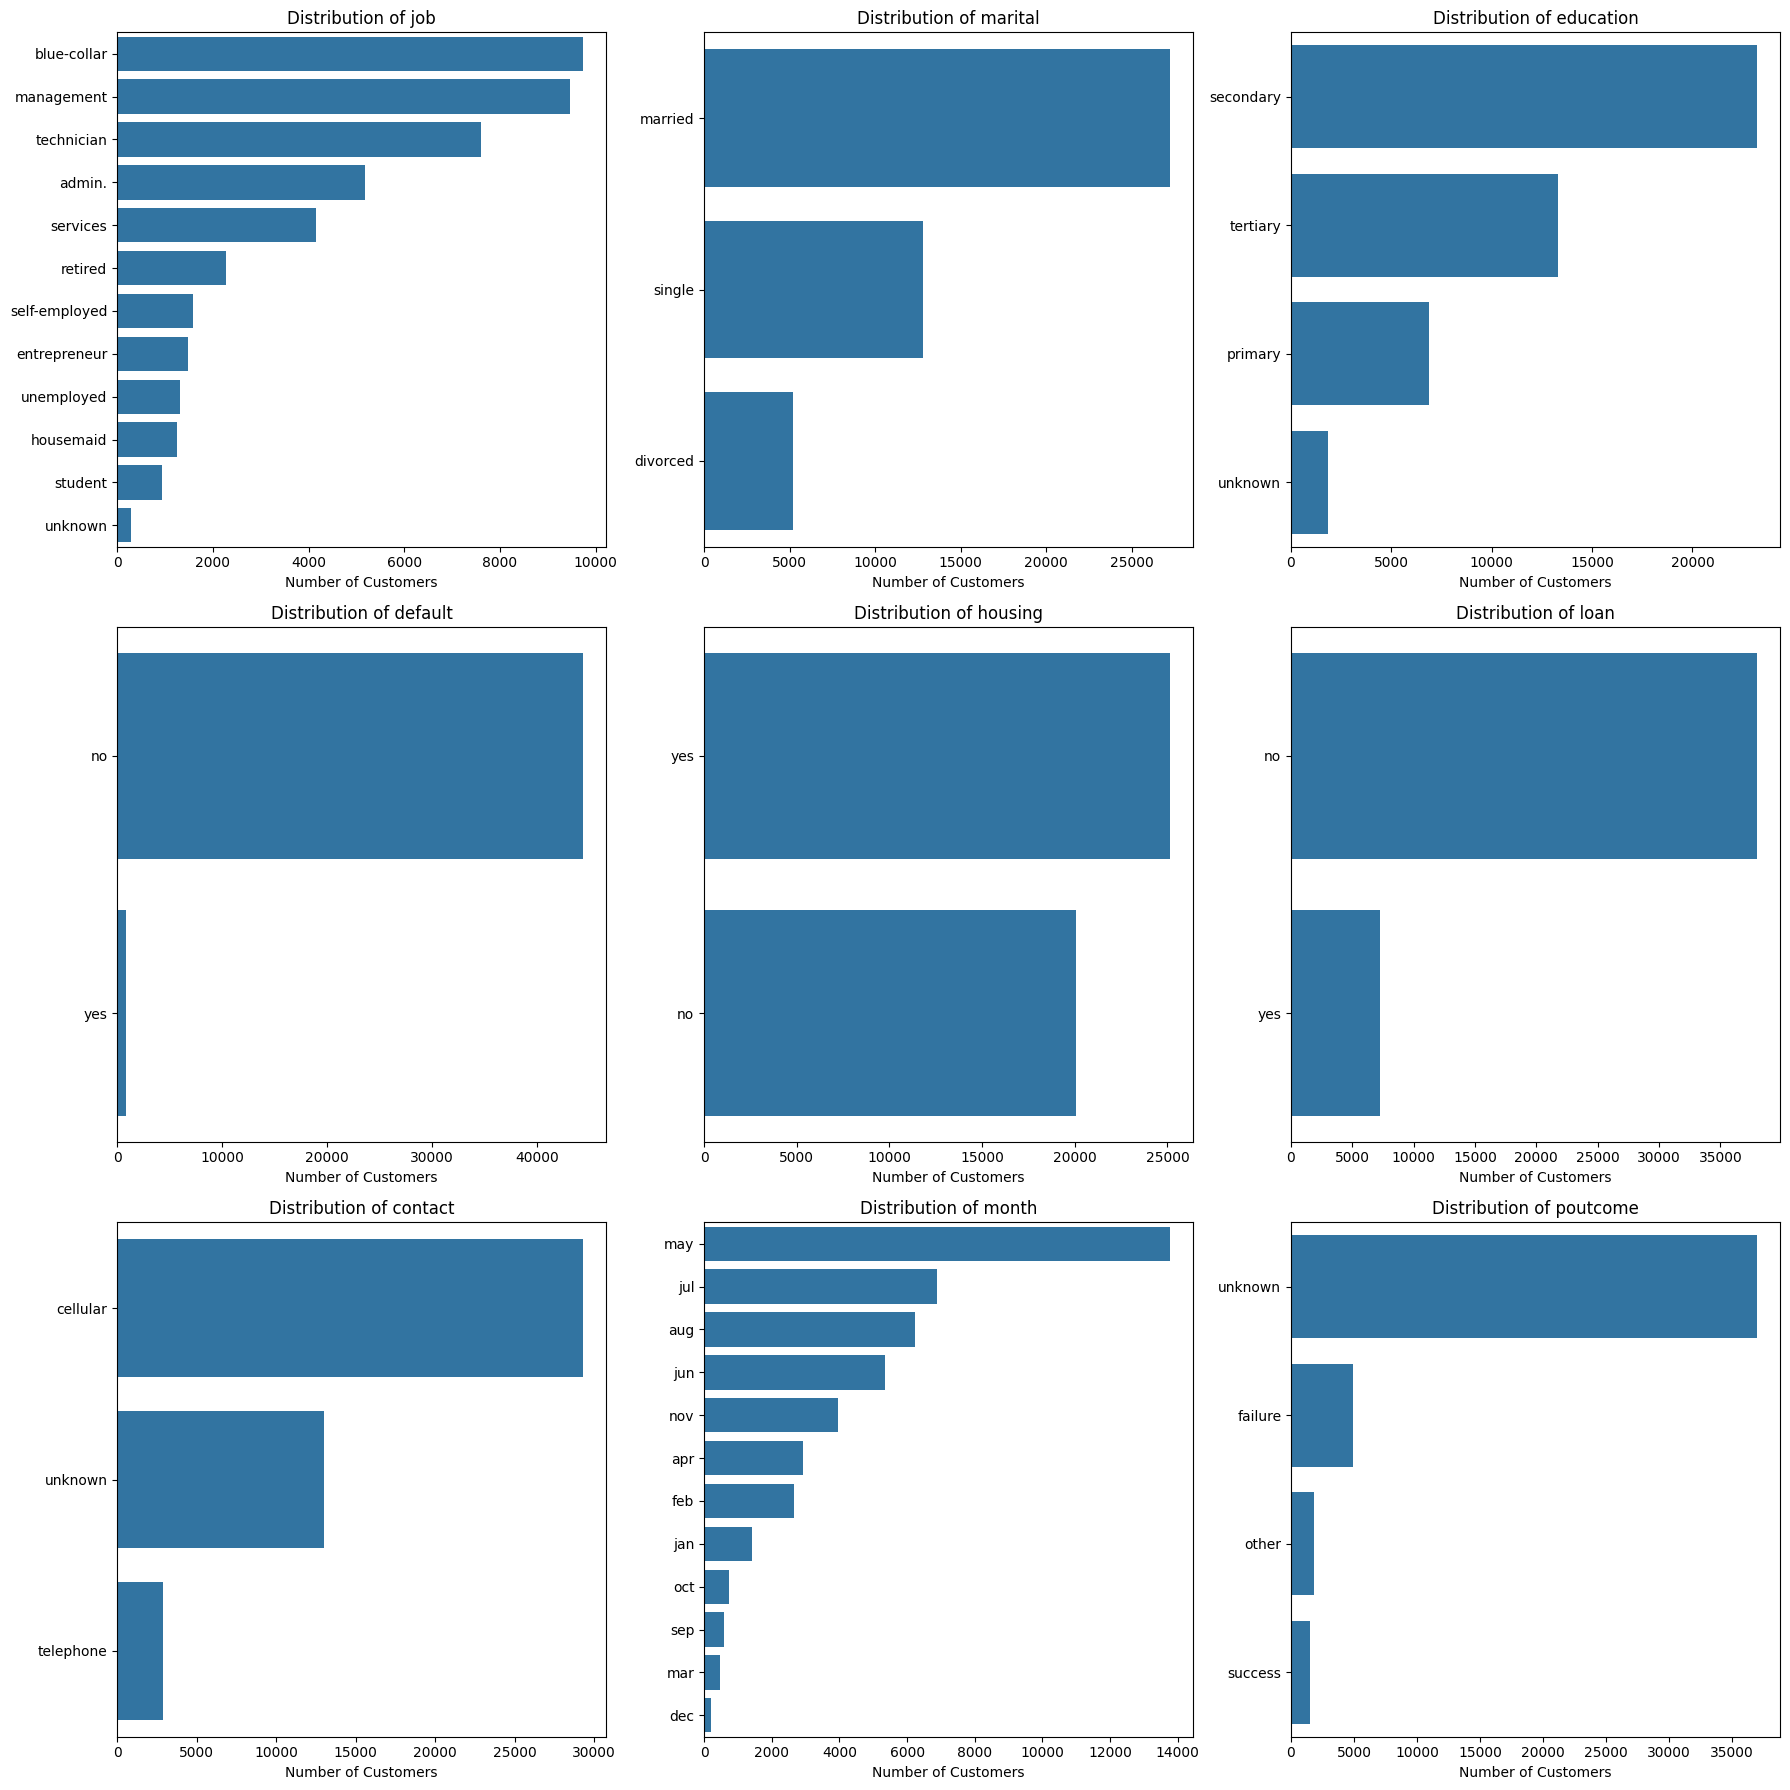

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Number of Customers")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

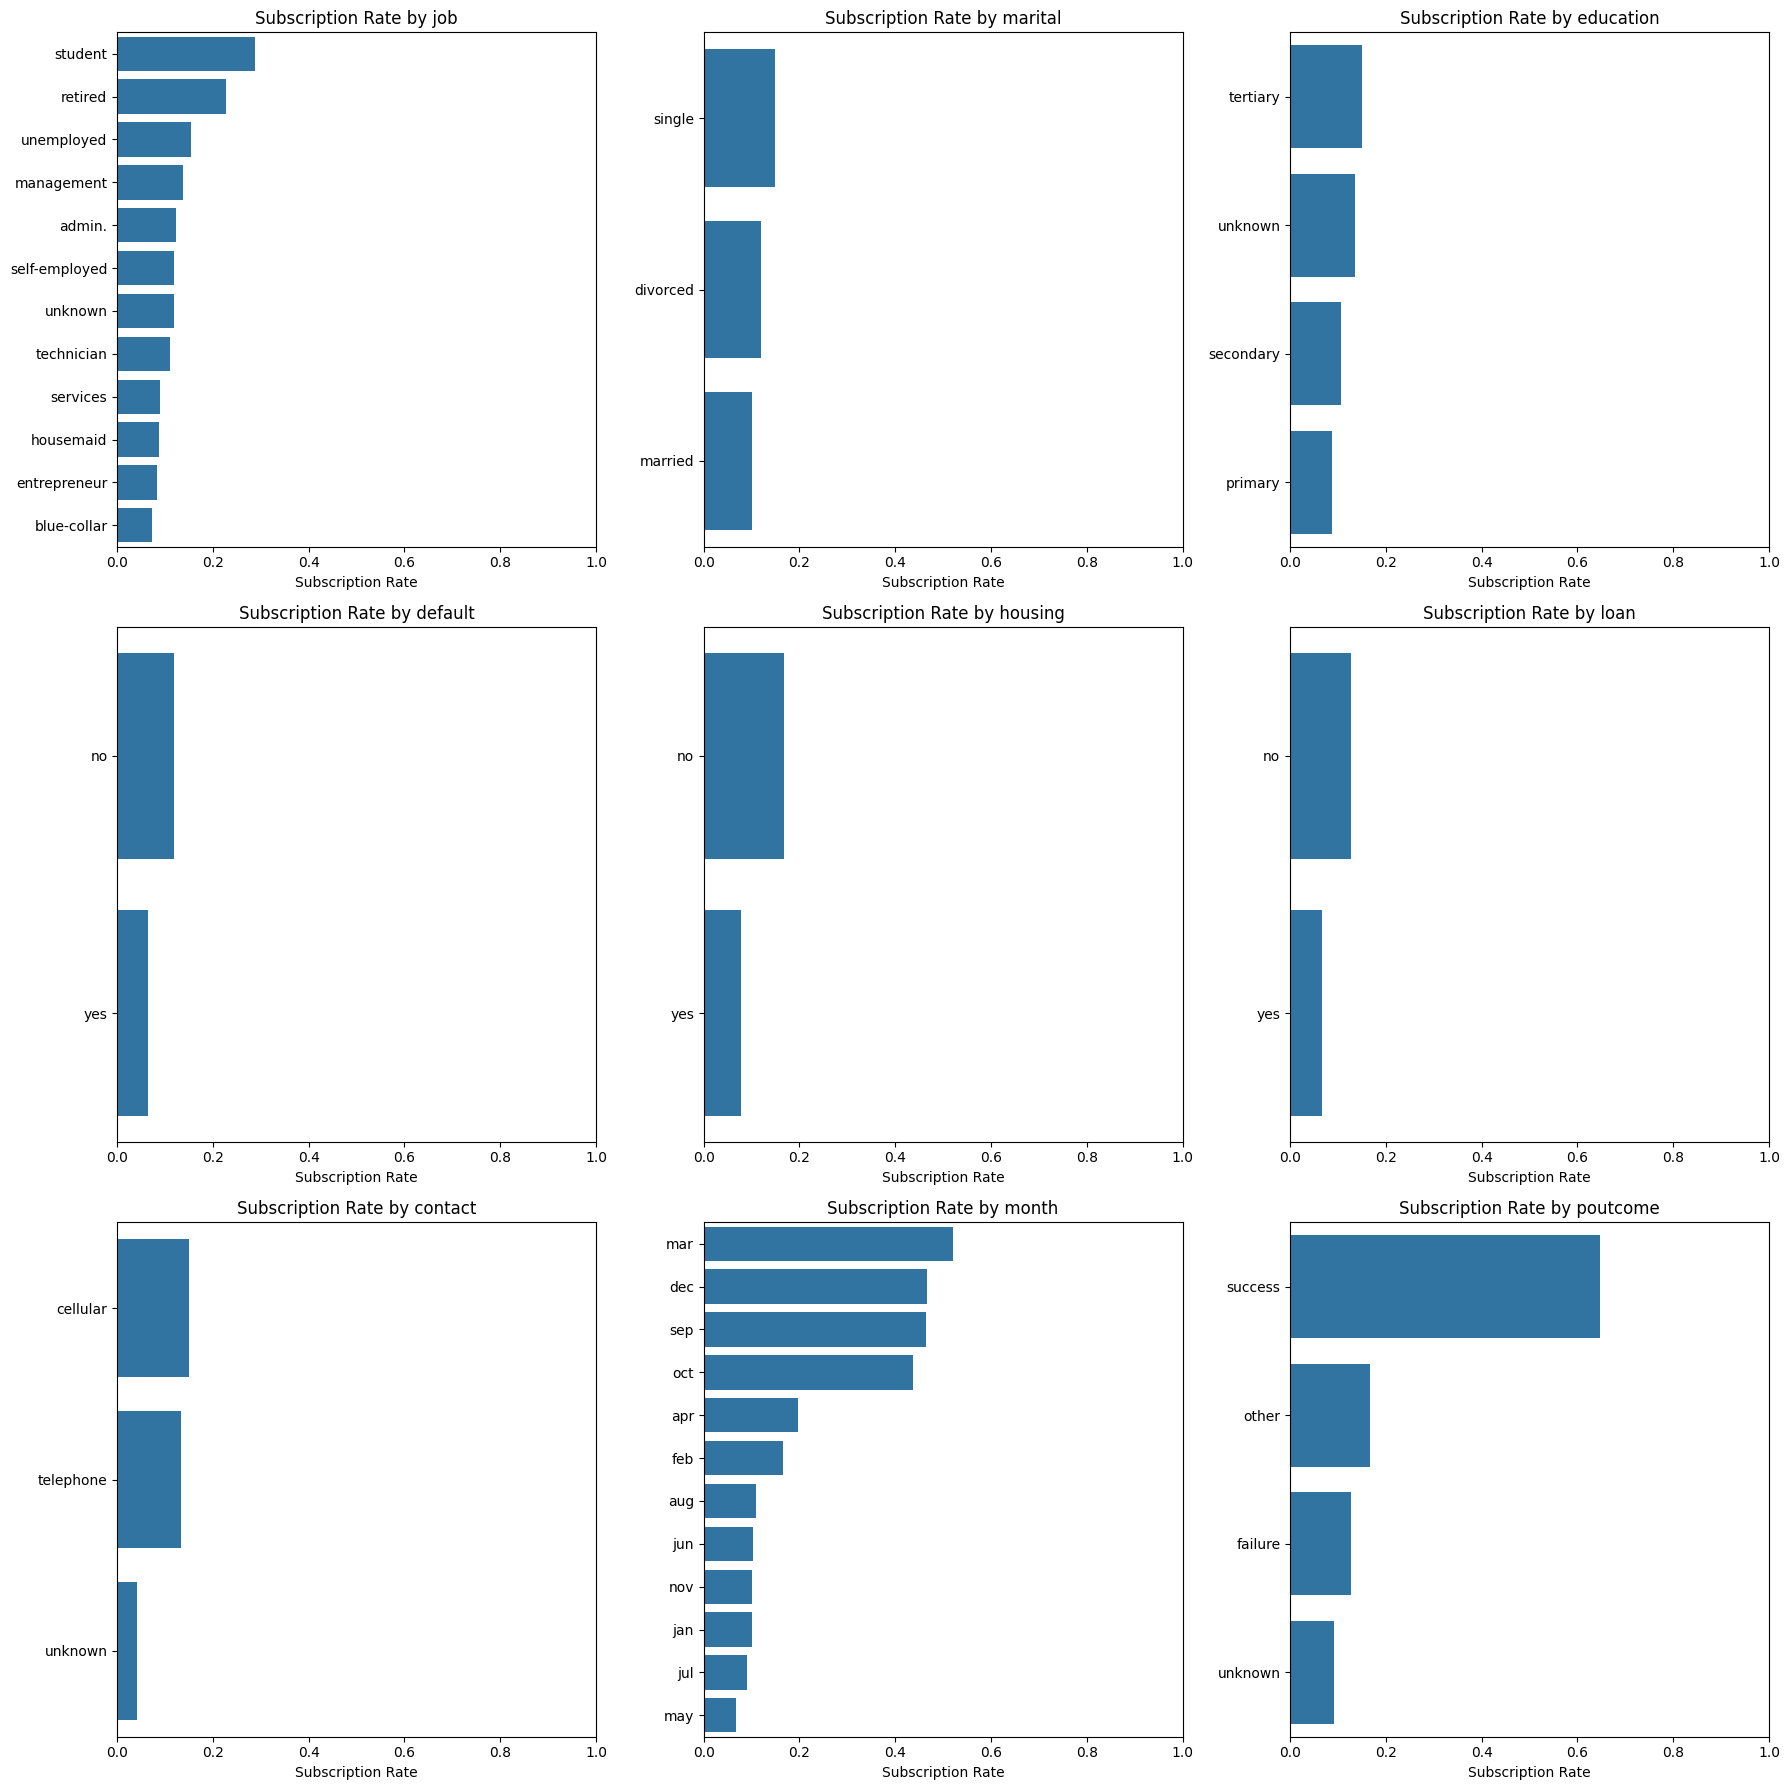

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    rates = (
        df.groupby(col, observed=False)["subscribed"]
        .mean()
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=rates.values,
        y=rates.index,
        ax=ax
    )

    ax.set_title(f"Subscription Rate by {col}")
    ax.set_xlabel("Subscription Rate")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

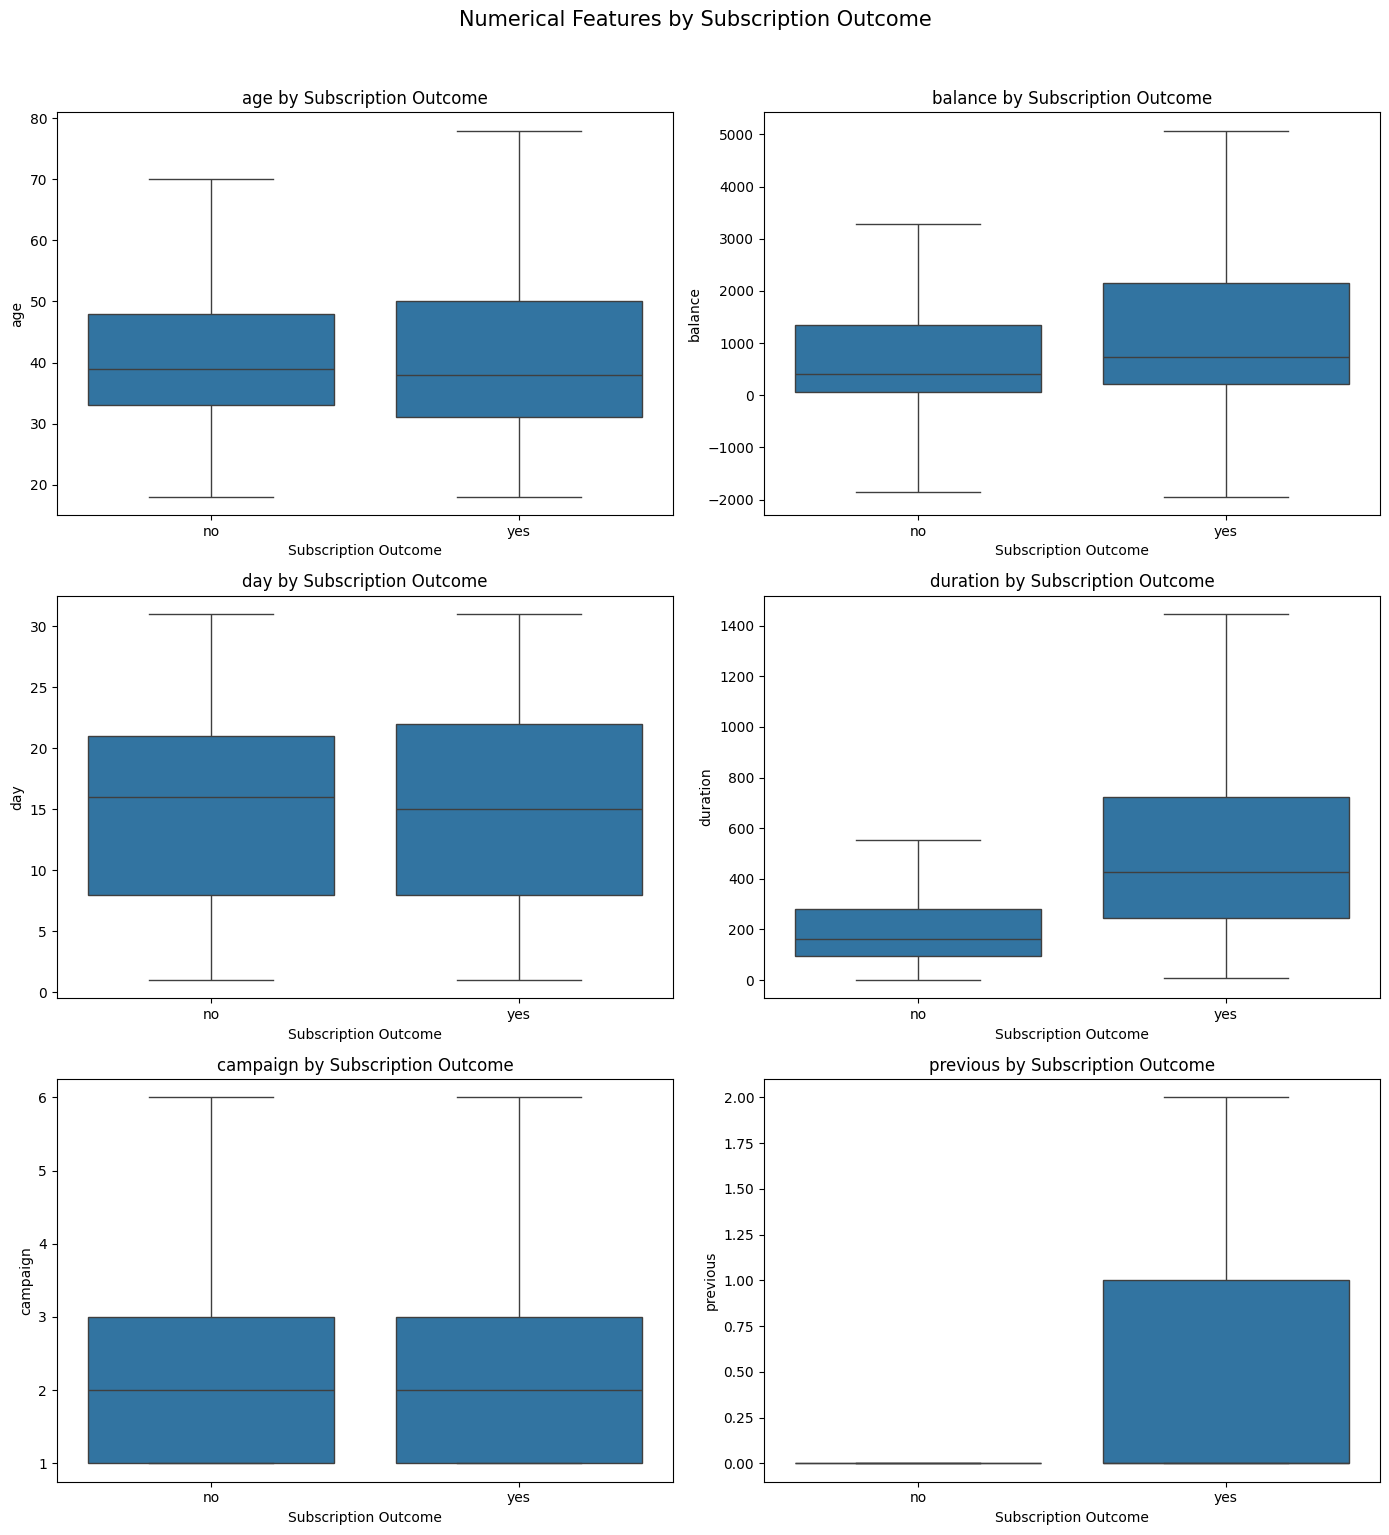

In [6]:
plot_cols = [col for col in numeric_cols if col != "pdays"]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for ax, col in zip(axes, plot_cols):
    sns.boxplot(
        data=df,
        x="y",
        y=col,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{col} by Subscription Outcome")
    ax.set_xlabel("Subscription Outcome")

for ax in axes[len(plot_cols):]:
    ax.remove()

plt.suptitle(
    "Numerical Features by Subscription Outcome",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()